In [15]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import pickle
from math import pi, sqrt


parent_dir = os.path.abspath("..")
if parent_dir not in sys.path:
    print(f"appending {parent_dir} to path")
    sys.path.append(parent_dir)

import src.unit_conv as conv

distance and energy

In [25]:
quantum_root = Path(parent_dir).parents[0]
fname = "./70x70x30small/all/time_evol_runs.pickle"
fname = quantum_root / fname

with open(fname, 'rb') as f:
    runs = pickle.load(f)

xr = runs[0]["r_right"][0][0]
xl = runs[0]["r_left"][0][0]
dist = [xr - xl]
times = [0]
n_part = runs[0]["n_part"]
Etot = runs[0]["energies"]["total"]

E_ext = [np.real(runs[0]["energies"]["ext"][0])]
for i, run in enumerate(runs):
    r_right = run["r_right"][0][1:]
    r_left = run["r_left"][0][1:]
    dist_ = r_right - r_left
    dist.extend(dist_.copy())

    times_ = np.arange(1, run["n_steps"] + 1)*run["timestep"]
    tend = times[-1]
    times.extend(tend + times_.copy())

    ext = run["energies"]["ext"][1:]
    E_ext.extend(np.real(ext.copy()))

dist = np.array(dist)
times = np.array(times)
E_ext = np.array(E_ext)

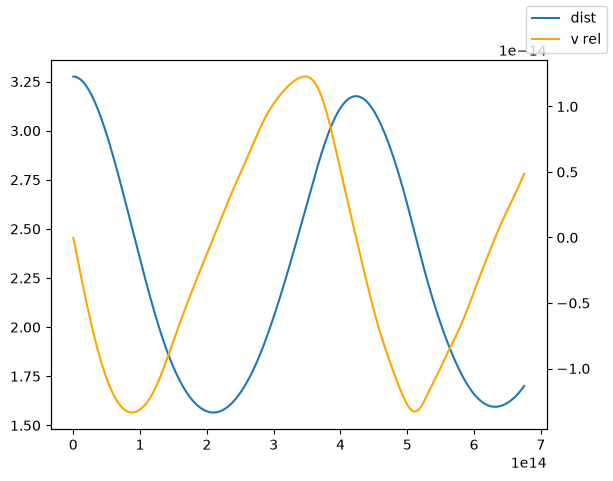

In [26]:
v_rel = np.empty_like(dist)
v_rel[0] = (dist[1] - dist[0])/(times[1] - times[0])
v_rel[-1] = (dist[-1] - dist[-2])/(times[-1] - times[-2])

p1 = slice(2, None, 1)
m1 = slice(0, -2, 1)
zero = slice(1, -1, 1)
v_rel[zero] = (dist[p1] - dist[m1])/2/(times[p1] - times[zero])
fig, ax = plt.subplots()
ax.plot(times, dist, label="dist")
ax2 = ax.twinx()
ax2.plot(times, v_rel, label="v rel", color="orange")
fig.legend()
plt.show()

Kinetic Energy

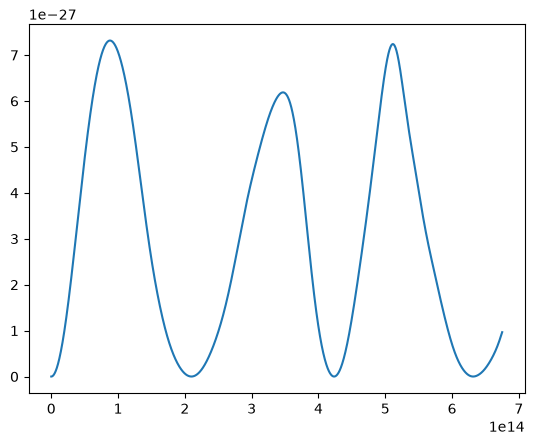

In [27]:
T = 0.25*163.929*v_rel**2
fig, ax = plt.subplots()
ax.plot(times, T)
plt.show()

Effective potential

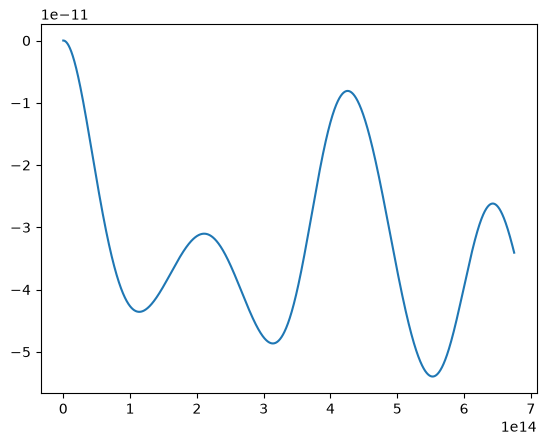

In [28]:
V_eff = E_ext - T
fig, ax = plt.subplots()
ax.plot(times, V_eff - V_eff[0])
plt.show()

In [29]:
def dd_classic(d, h):
    add = 131
    m = 163.929
    rho = (n_part/2/h)
    cdd = 12*pi*add/m/conv.mum_to_atm**3
    d = d*conv.mum_to_atm
    return cdd/4/pi*rho**2/d*2*(1 - 1/sqrt((h/d)**2 + 1))

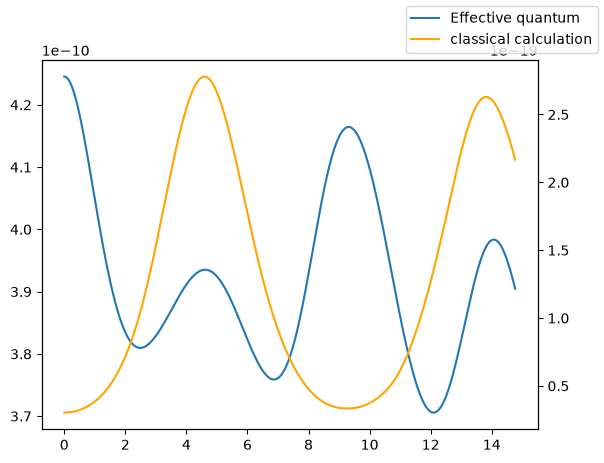

In [30]:
v_class = np.empty_like(times)
for i in range(times.shape[0]):
    v_class[i] = dd_classic(dist[i], 5)

fig, ax = plt.subplots()
ax.plot(times*conv.jat_to_ms, V_eff, label="Effective quantum")
ax2 = ax.twinx()
ax2.plot(times*conv.jat_to_ms, v_class, label="classical calculation", color="orange")
fig.legend()
plt.show()